# PRCL-0015 · Bank GoodCredit
## Notebook 3: Model Building & Evaluation

**Goal:** beat the benchmark **Gini 37.9** with clean rank ordering (bad rate should fall from decile 10 to decile 1).

**Approach** (`src/train.py`)
1. Stratified 70/30 train/test split
2. Feature selection on train data only: remove |corr| > 0.95, then a **shadow-feature test** — add shuffled copies of real columns as pure noise and keep only features that earn more XGBoost gain than the best noise column
3. Train Logistic Regression, Random Forest, XGBoost, LightGBM and an Ensemble
4. 5-fold CV Gini on train + test Gini, decile rank ordering, KS
5. Pick the model with the fewest rank-order breaks, then highest test Gini; calibrate its probabilities to the real bad rate

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid', palette='deep')
RAW = os.path.join(ROOT, 'data', 'raw')
from IPython.display import Image, display
REP = os.path.join(ROOT, 'reports'); FIG = os.path.join(REP, 'figures')

## 1. Train all models

In [2]:
import train
res, ro, fm = train.main()

Data: (15000, 121), bad rate 5.05%


Features: 121 -> 121 after corr filter -> 50 beat the noise threshold


  Logistic Regression  CV 48.4  train 54.8  test 50.8


  Random Forest        CV 49.7  train 89.2  test 50.0


  XGBoost              CV 49.3  train 74.6  test 48.9


  LightGBM             CV 48.5  train 75.8  test 47.2
  Ensemble             train 69.0  test 49.7


Calibration: mean predicted PD 5.127% vs actual test bad rate 5.044%

Best model: Logistic Regression  test Gini 50.80 (benchmark 37.9)  rank breaks 1
        customers  bads  bad_rate  benchmark_bad_rate       KS
decile                                                        
10            450    85    0.1889              0.1171  28.9029
9             450    40    0.0889              0.0805  36.9289
8             450    22    0.0489              0.0600  36.6042
7             450    19    0.0422              0.0396  34.8876
6             450    18    0.0400              0.0425  32.7072
5             450    15    0.0333              0.0366  29.1349
4             450    11    0.0244              0.0205  23.7069
3             450    12    0.0267              0.0205  18.7428
2             450     3    0.0067              0.0205   9.6034
1             450     2    0.0044              0.0132   0.0000



Saved -> models/credit_score_model.pkl, reports/*.csv, reports/figures/*.png


## 2. Model comparison

,model,cv_gini,train_gini,test_gini,rank_breaks,beats_benchmark
0,Logistic Regression,48.36,54.85,50.80,1,True
1,Random Forest,49.66,89.25,50.02,1,True
2,XGBoost,49.30,74.64,48.89,2,True
3,LightGBM,48.47,75.84,47.18,2,True
4,Ensemble,NaN,69.01,49.65,3,True


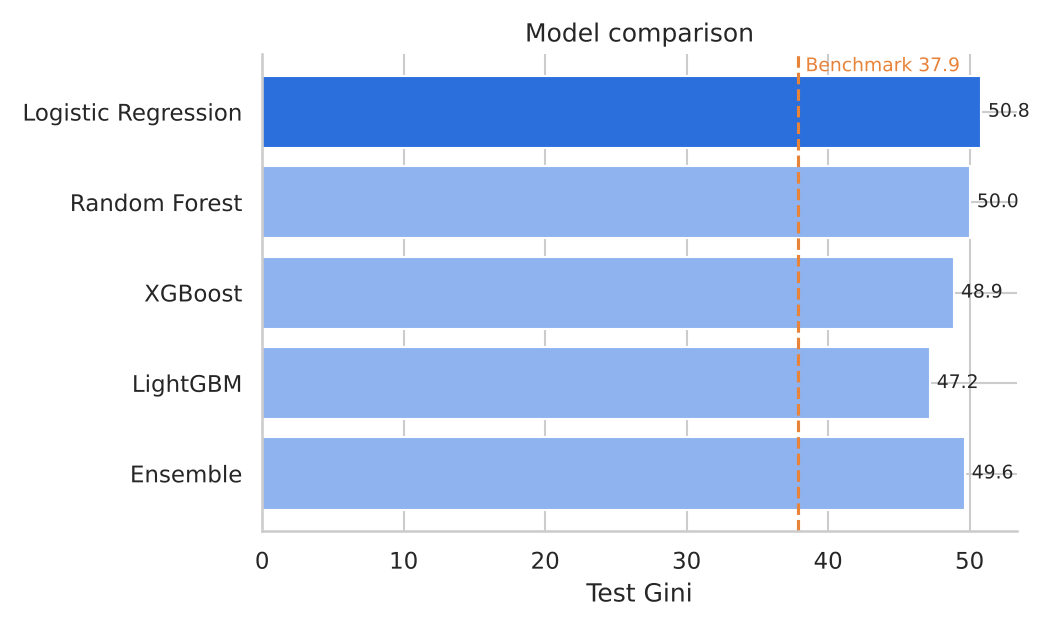

In [3]:
display(res)
display(Image(os.path.join(FIG, 'model_comparison.png'), width=600))

**Reading this:** every model beats the benchmark Gini of 37.9. Logistic Regression has the best test Gini and the cleanest rank ordering. It also generalises best: its train and test Gini are close, while the tree models score much higher on train than on test, which means they overfit. With ~750 bad customers, a regularised linear model on well-engineered features is hard to beat. It is also the easiest model to explain to credit-risk and audit teams.

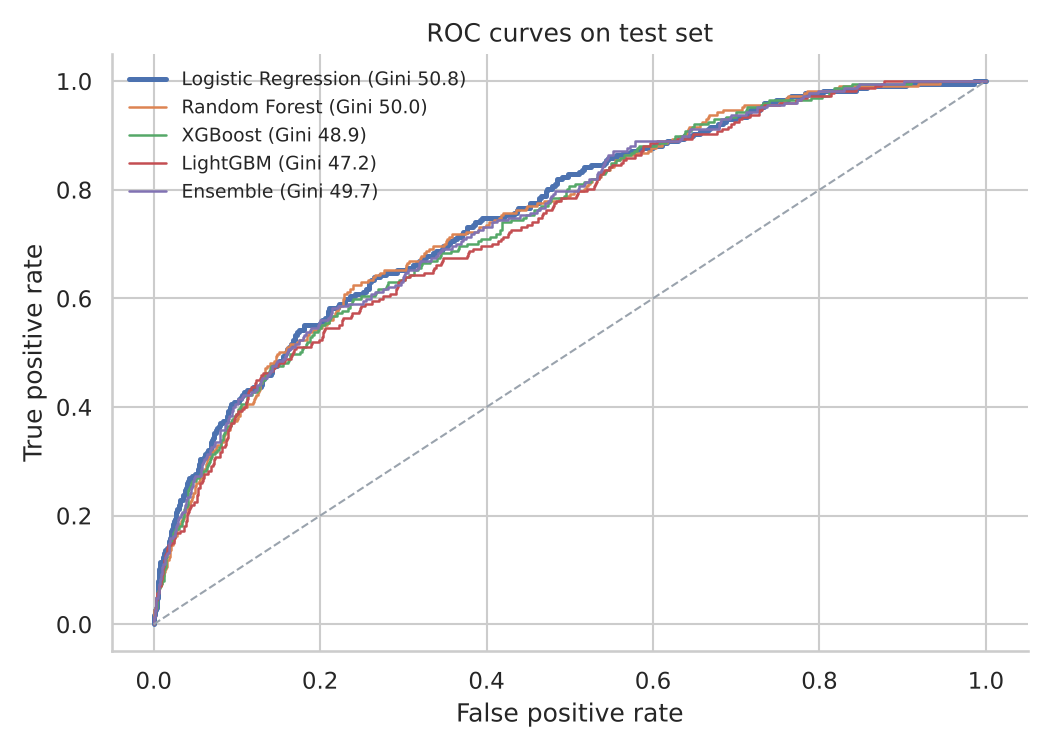

In [4]:
display(Image(os.path.join(FIG, 'roc_curves.png'), width=600))

## 3. Rank ordering (best model vs benchmark)

,customers,bads,bad_rate,benchmark_bad_rate,cum_bads_pct,KS
decile,,,,,,
10,450,85,18.89%,11.71%,37.4%,28.9
9,450,40,8.89%,8.05%,55.1%,36.9
8,450,22,4.89%,6.0%,64.8%,36.6
7,450,19,4.22%,3.96%,73.1%,34.9
6,450,18,4.0%,4.25%,81.1%,32.7
5,450,15,3.33%,3.66%,87.7%,29.1
4,450,11,2.44%,2.05%,92.5%,23.7
3,450,12,2.67%,2.05%,97.8%,18.7
2,450,3,0.67%,2.05%,99.1%,9.6


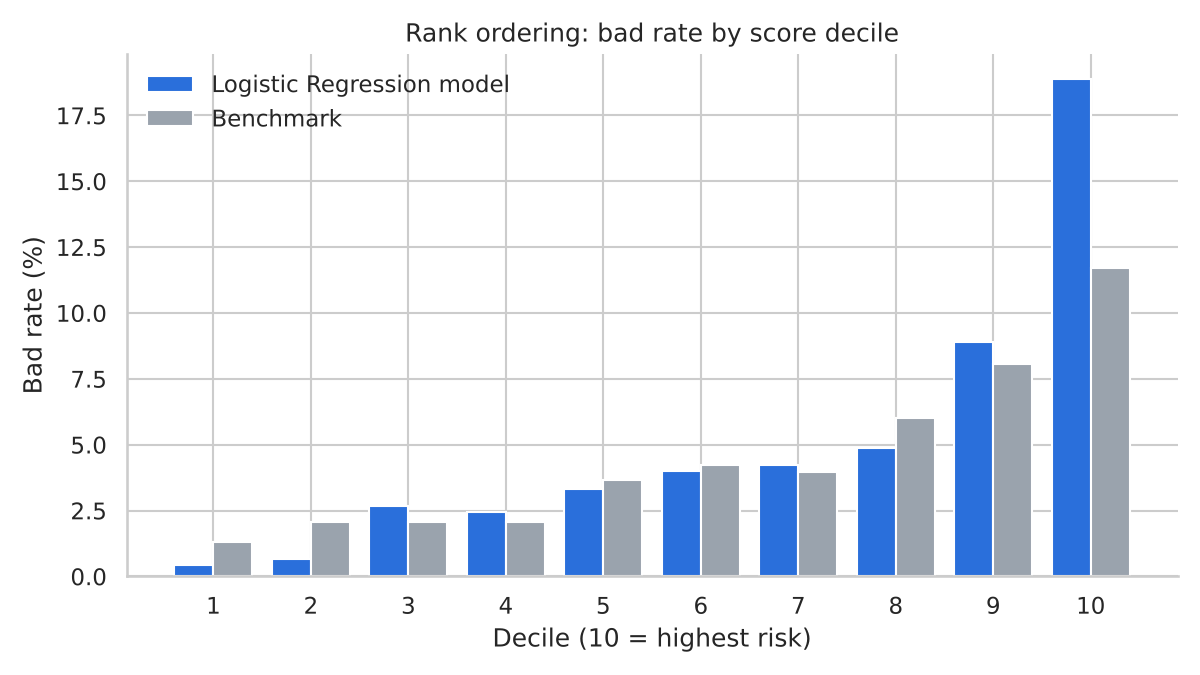

In [5]:
show = ro[['customers', 'bads', 'bad_rate', 'benchmark_bad_rate', 'cum_bads_pct', 'KS']].copy()
show['bad_rate'] = (show['bad_rate'] * 100).round(2).astype(str) + '%'
show['benchmark_bad_rate'] = (show['benchmark_bad_rate'] * 100).round(2).astype(str) + '%'
show['cum_bads_pct'] = (show['cum_bads_pct'] * 100).round(1).astype(str) + '%'
show['KS'] = show['KS'].round(1)
display(show)
display(Image(os.path.join(FIG, 'rank_ordering.png'), width=650))

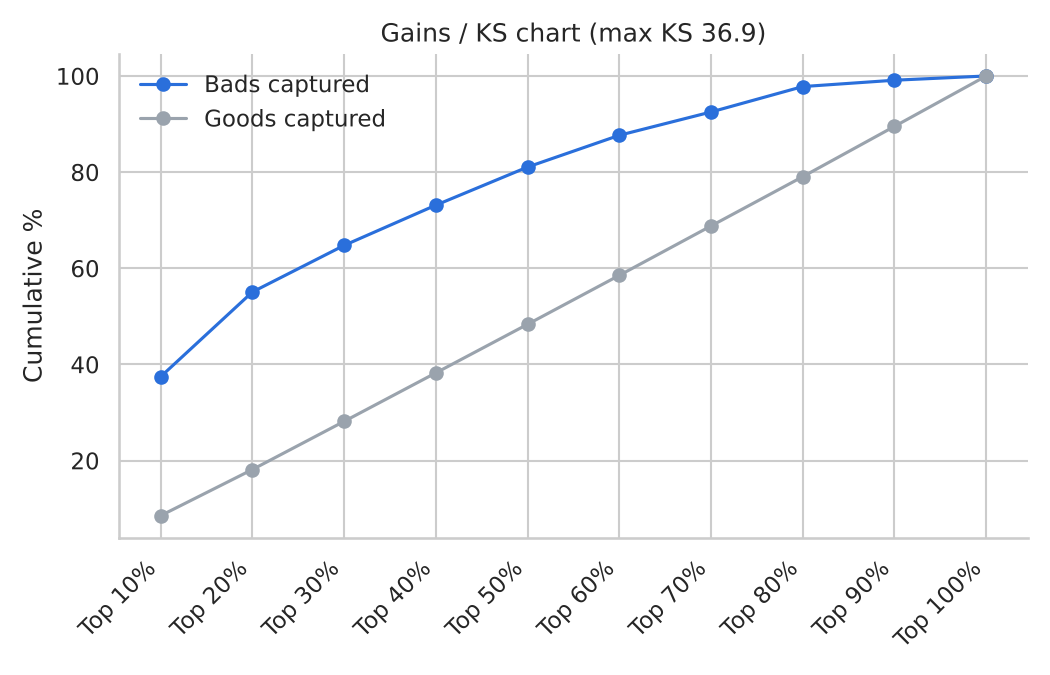

In [6]:
display(Image(os.path.join(FIG, 'gains_ks_chart.png'), width=600))

## 4. Feature matrix — selected features with gain

In [7]:
print(f'{len(fm)} features selected')
display(fm.head(25).style.format({'gain': '{:.4f}'}).bar(subset=['gain'], color='#8fb3ee'))
display(fm.groupby('source')['gain'].agg(['count', 'sum']).round(3).rename(columns={'count': 'n_features', 'sum': 'total_gain'}))

50 features selected


,feature,gain,source
1,mean_dpd,0.1151,Account
2,n_accounts_ever_30p,0.1084,Account
3,pct_accounts_ever_30p,0.0499,Account
4,payment_history_avg_dpd_0_29_bucket,0.0345,Account
5,payment_history_total_dpd_0_29,0.0311,Account
6,count_enquiry_recency_365,0.0302,Enquiry
7,Ratio_currbalance_creditlimit,0.0254,Account
8,ratio_balance_high_credit,0.0224,Account
9,count_enquiry,0.0223,Enquiry
10,count_enquiry_recency_180,0.0220,Enquiry


,n_features,total_gain
source,,
Account,15,0.495
Demographics,27,0.350
Enquiry,8,0.156


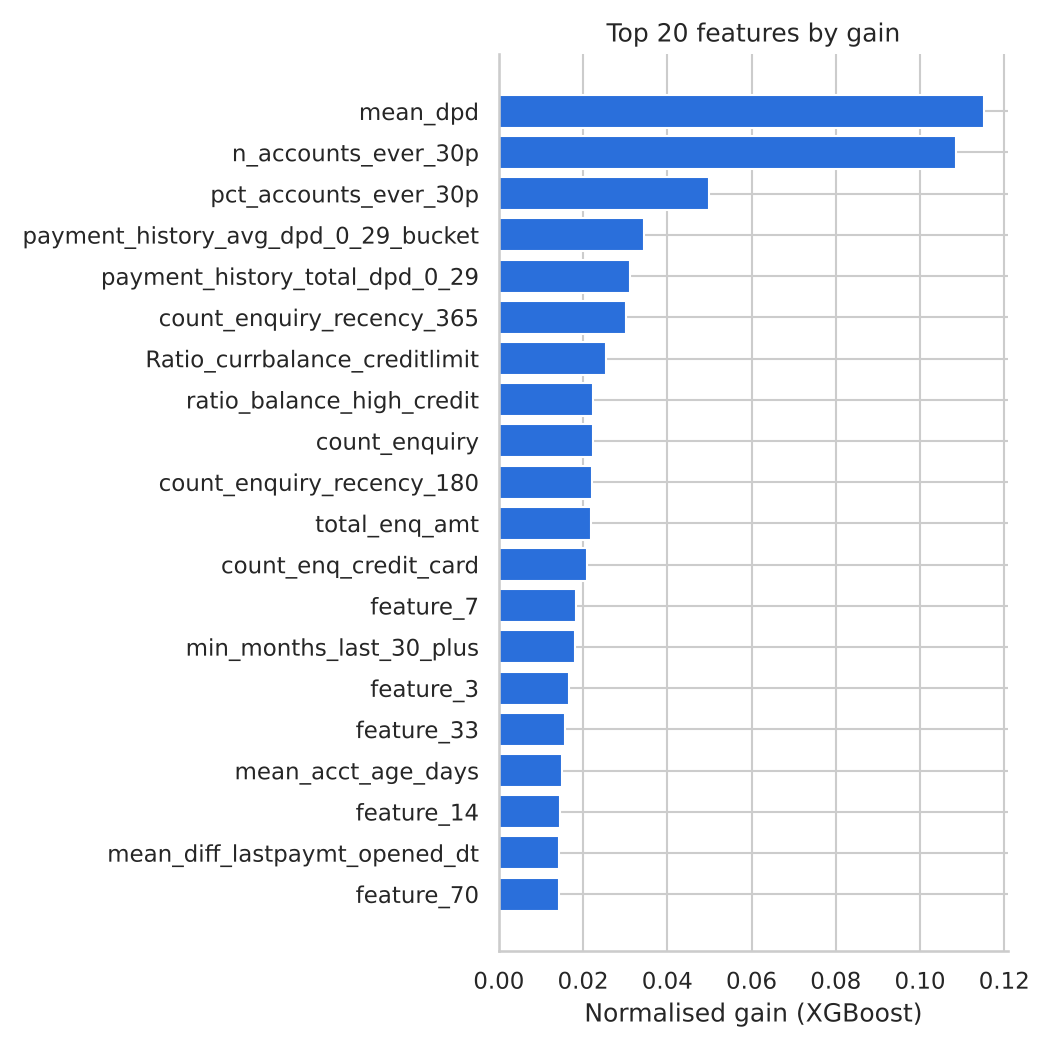

In [8]:
display(Image(os.path.join(FIG, 'feature_gain_top20.png'), width=600))

## 5. Scoring customers (cred score 300–900)

In [9]:
import subprocess
print(subprocess.run([sys.executable, os.path.join(ROOT, 'src', 'predict.py')], capture_output=True, text=True).stdout)
scores = pd.read_csv(os.path.join(REP, 'customer_cred_scores.csv'))
y = pd.read_csv(os.path.join(RAW, 'customer_demographics.csv'), usecols=['customer_no', 'Bad_label'])
s = scores.merge(y, on='customer_no')
order = ['Very High Risk', 'High Risk', 'Medium Risk', 'Low Risk', 'Very Low Risk']
band = s.groupby('risk_band').agg(customers=('customer_no', 'size'), actual_bad_rate=('Bad_label', 'mean'), avg_score=('cred_score', 'mean')).reindex(order)
band['actual_bad_rate'] = (band['actual_bad_rate'] * 100).round(2)
band['avg_score'] = band['avg_score'].round(0)
band

Scored 15000 customers with Logistic Regression -> /home/claude/PRCL-0015_Bank_GoodCredit/reports/customer_cred_scores.csv
risk_band
Very High Risk     217
High Risk         2868
Medium Risk       7827
Low Risk          3832
Very Low Risk      256



,customers,actual_bad_rate,avg_score
risk_band,,,
Very High Risk,217,34.10,479.0
High Risk,2868,12.34,552.0
Medium Risk,7827,3.73,617.0
Low Risk,3832,0.91,673.0
Very Low Risk,256,0.78,736.0


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(s.loc[s.Bad_label == 0, 'cred_score'], bins=40, alpha=.7, label='Good', color='#2a6fdb', density=True)
ax.hist(s.loc[s.Bad_label == 1, 'cred_score'], bins=40, alpha=.7, label='Bad', color='#e8833a', density=True)
ax.set(xlabel='Cred score', title='Cred score distribution — good vs bad customers'); ax.legend(); plt.show()

## 6. Conclusion

| Project goal | Result |
|---|---|
| **1. Data exploration insights** | Notebook 1 — 10 findings, each with the decision taken (imbalance handling, payment-history parsing, utilisation, enquiry recency, dropping empty/constant/ID columns) |
| **2. Feature matrix with gain** | `reports/feature_matrix_gain.csv` — selected features ranked by XGBoost gain; past-delinquency and DPD-bucket features lead, followed by enquiry recency and utilisation, which matches the business case suggestions |
| **3. Model evaluation** | Test Gini **≈ 50.8 vs benchmark 37.9**; bad rate falls from ≈ 19% in decile 10 to < 1% in decile 1, with one small break (deciles 3/4 differ by one customer) |

**Business use:** customers below a cred score of ~580 (High / Very High risk) can be routed to limit review, while Low / Very Low risk customers are candidates for limit increases or cross-sell.

**Next steps on real data:** run `src/fetch_from_mysql.py`, rerun the pipeline, check population stability (PSI) between train and the current portfolio, and tune the score cut-offs with the risk team.